# Cleaning and Analysis

**Question:** *What makes a mortgage cost more?*

This notebook starts from the file prepared in notebook 01 (1,747,609 applications, 16 columns) and:
1. Shows what happened to each application
2. Keeps approved loans (the only ones with a price)
3. Checks data quality
4. Cleans the data
5. Creates features for the analysis and the app
6. Checks the distribution of prices
7. Answers Question 1: does a smaller down payment cost more?
8. Answers Question 2: do closing costs differ across states?

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

YEAR = 2025
STATES = ["CA", "MA", "FL", "TX", "MI", "OH"]
STATE_TIERS = {"CA": "Expensive", "MA": "Expensive", "FL": "Mid",
               "TX": "Mid", "MI": "Low", "OH": "Low"}

# Folders: full path to the project folder
PROJECT_DIR = Path(r"C:\Users\havil\CMSE_midterm_HMDA_project")
INTERIM_DIR = PROJECT_DIR / "data" / "interim"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Load the file saved by notebook 01
scoped = pd.read_parquet(INTERIM_DIR / f"hmda_{YEAR}_purchase_filtered.parquet", dtype_backend="pyarrow")
print(f"Loaded {len(scoped):,} rows x {scoped.shape[1]} columns")

Loaded 1,747,609 rows x 16 columns


## Step 1 · What happened to each application?

`action_taken` records each outcome: **1** = loan made, 2 = approved but not accepted, **3** = denied,
4 = withdrawn, 5 = incomplete, 6 = purchased loan (bought from another lender), 7/8 = preapproval outcomes.

The table shows the % of each outcome in each state.

In [3]:
OUTCOMES = {"1": "Originated", "2": "Approved, not accepted", "3": "Denied",
            "4": "Withdrawn", "5": "Incomplete", "6": "Purchased loan",
            "7": "Preapproval denied", "8": "Preapproval approved, not accepted"}
scoped["outcome"] = scoped["action_taken"].astype(str).map(OUTCOMES)

outcome_table = pd.crosstab(scoped["state_code"], scoped["outcome"], normalize="index") * 100
display(outcome_table.loc[STATES].round(1))

outcome,"Approved, not accepted",Denied,Incomplete,Originated,"Preapproval approved, not accepted",Preapproval denied,Purchased loan,Withdrawn
state_code,,,,,,,,
CA,2.0,5.6,1.4,55.9,1.7,0.2,19.1,14.1
MA,1.1,4.1,1.6,59.4,2.0,0.3,19.8,11.6
FL,1.4,8.1,1.4,53.9,1.0,0.2,21.0,13.0
TX,1.7,6.2,1.4,52.9,1.1,0.2,23.6,12.8
MI,1.4,5.5,1.7,63.5,2.7,0.3,12.3,12.5
OH,1.4,4.6,1.4,58.6,1.6,0.3,18.8,13.3


## Step 2 · Keep approved loans only (D7)

A price exists only when a loan was actually made. For denied or withdrawn applications, the price
fields are blank by design, so they are not imputed. The analysis uses approved loans (`action_taken = 1`).

In [4]:
df = scoped[scoped["action_taken"] == "1"].reset_index(drop=True)
df = df.drop(columns=["outcome"])

print(f"Approved loans: {len(df):,} rows x {df.shape[1]} columns")
print(df["state_code"].value_counts())

Approved loans: 970,201 rows x 16 columns
state_code
TX    292354
FL    225732
CA    205767
OH    109912
MI     86675
MA     49761
Name: count, dtype: int64[pyarrow]


## Step 3 · Check data quality

All columns are still text, so HMDA's codes can be counted: `NA` = not applicable or not reported,
`Exempt` = small lender not required to report. We also look for impossible values and check how
mixed the loans are (loan term, fixed vs adjustable rate), since that affects price comparisons.
Nothing is changed here.

In [5]:
# 1. Missing values (HMDA writes them as "NA" or "Exempt")
print("1. Missing values (% of loans)")
for col in ["interest_rate", "rate_spread", "total_loan_costs", "loan_to_value_ratio", "income"]:
    pct_na = (df[col] == "NA").mean() * 100
    pct_exempt = (df[col] == "Exempt").mean() * 100
    print(f"   {col}: NA = {pct_na:.2f}%, Exempt = {pct_exempt:.2f}%")

# 2. Impossible or suspicious values (text converted to numbers just for checking)
rate = pd.to_numeric(df["interest_rate"].astype(str), errors="coerce")
spread = pd.to_numeric(df["rate_spread"].astype(str), errors="coerce")
ltv = pd.to_numeric(df["loan_to_value_ratio"].astype(str), errors="coerce")
income = pd.to_numeric(df["income"].astype(str), errors="coerce")

print("\n2. Impossible or suspicious values (number of loans)")
print("   Interest rate below 0.5% or above 15%:", ((rate < 0.5) | (rate > 15)).sum())
print("   Loan-to-value above 150%:", (ltv > 150).sum())
print("   Rate spread below -5 or above 10:", ((spread < -5) | (spread > 10)).sum())
print("   Income zero or negative:", (income <= 0).sum())

# 3. Loan term
print("\n3. Loan term in months (%):")
print((df["loan_term"].value_counts(normalize=True) * 100).round(1).head())

# 4. Fixed vs adjustable (fixed-rate loans have "NA" in intro_rate_period)
print("\n4. Fixed rate (True) vs adjustable (False), %:")
print(((df["intro_rate_period"] == "NA").value_counts(normalize=True) * 100).round(1))

# 5. Inconsistent categories: debt-to-income mixes ranges and exact numbers
print("\n5. Debt-to-income values (top 10):")
print(df["debt_to_income_ratio"].value_counts().head(10))

1. Missing values (% of loans)
   interest_rate: NA = 0.03%, Exempt = 1.38%
   rate_spread: NA = 0.71%, Exempt = 1.38%
   total_loan_costs: NA = 1.59%, Exempt = 1.38%
   loan_to_value_ratio: NA = 2.69%, Exempt = 1.38%
   income: NA = 0.92%, Exempt = 0.00%

2. Impossible or suspicious values (number of loans)
   Interest rate below 0.5% or above 15%: 304
   Loan-to-value above 150%: 37
   Rate spread below -5 or above 10: 899
   Income zero or negative: 3825

3. Loan term in months (%):
loan_term
360       93.9
180        2.1
Exempt     1.4
240        0.7
372        0.4
Name: proportion, dtype: double[pyarrow]

4. Fixed rate (True) vs adjustable (False), %:
intro_rate_period
True     90.4
False     9.6
Name: proportion, dtype: double[pyarrow]

5. Debt-to-income values (top 10):
debt_to_income_ratio
30%-<36%    133227
50%-60%     117174
20%-<30%    110290
49           66224
48           44885
44           43361
47           40942
42           40275
43           39740
46           38793
N

## Step 4 · Clean the data

- **Text → numbers.** `NA` and `Exempt` become missing values (`NaN`).
- **Keep comparable loans (D9):** 30-year, fixed-rate loans with regular payments. 15-year,
  adjustable-rate, interest-only and balloon loans are priced differently.
- **Remove impossible values (D10):** interest rates outside 0.5–15%, loan-to-value outside 1–150%,
  rate spreads outside −5 to +10 (e.g. −414).

Extreme but possible values are kept, because the analysis uses medians, which they don't distort.

In [6]:
# Text -> numbers ("NA" and "Exempt" become NaN)
for col in ["interest_rate", "rate_spread", "total_loan_costs", "loan_amount",
            "loan_to_value_ratio", "property_value", "income", "loan_term"]:
    df[col] = pd.to_numeric(df[col].astype(str), errors="coerce")

# Filters, recording how many rows remain after each
counts = [("Approved loans", len(df))]
df = df[df["loan_term"] == 360];                    counts.append(("30-year term", len(df)))
df = df[df["intro_rate_period"] == "NA"];           counts.append(("Fixed rate", len(df)))
df = df[df["interest_only_payment"] != "1"];        counts.append(("Not interest-only", len(df)))
df = df[df["balloon_payment"] != "1"];              counts.append(("No balloon payment", len(df)))
df = df[df["interest_rate"].between(0.5, 15)];      counts.append(("Valid interest rate", len(df)))
df = df[df["loan_to_value_ratio"].between(1, 150)]; counts.append(("Valid loan-to-value", len(df)))
df = df[df["rate_spread"].between(-5, 10) | df["rate_spread"].isna()]; counts.append(("Valid rate spread", len(df)))

clean_funnel = pd.DataFrame(counts, columns=["step", "rows_remaining"])
clean_funnel["removed"] = clean_funnel["rows_remaining"].diff().fillna(0).abs().astype(int)
display(clean_funnel)

# Save for the app's Data & Preparation page
clean_funnel.to_csv(PROJECT_DIR / "data" / "funnel_cleaning.csv", index=False)

,step,rows_remaining,removed
0,Approved loans,970201,0
1,30-year term,911243,58958
2,Fixed rate,836428,74815
3,Not interest-only,834944,1484
4,No balloon payment,834839,105
5,Valid interest rate,834352,487
6,Valid loan-to-value,810854,23498
7,Valid rate spread,810670,184


## Step 5 · Create features and save (D11)

| New column | Built from | Values |
|---|---|---|
| `down_payment_band` | loan-to-value | 20%+ down (LTV ≤ 80), 10–20%, 5–10%, 3–5%, under 3% |
| `loan_costs_pct` | total loan costs ÷ loan amount × 100 | closing costs as % of the loan |
| `loan_type_label` | loan type code | Conventional, FHA, VA, USDA |
| `tier` | state | Expensive, Mid, Low |

The band cut-offs follow mortgage rules: below 20% down usually requires mortgage insurance, and 3%
is the lowest conventional down payment. The cleaned data is saved for the Streamlit app.

In [7]:
df["loan_type_label"] = df["loan_type"].astype(str).map({"1": "Conventional", "2": "FHA", "3": "VA", "4": "USDA"})
df["tier"] = df["state_code"].astype(str).map(STATE_TIERS)

df["down_payment_band"] = pd.cut(df["loan_to_value_ratio"],
                                 bins=[0, 80, 90, 95, 97, 150],
                                 labels=["20%+ down", "10-20% down", "5-10% down", "3-5% down", "Under 3% down"])

df["loan_costs_pct"] = df["total_loan_costs"] / df["loan_amount"] * 100

print(df["down_payment_band"].value_counts().sort_index())

# Save only the columns the analysis and the app need
APP_COLS = ["state_code", "tier", "loan_type_label", "interest_rate", "rate_spread",
            "total_loan_costs", "loan_costs_pct", "loan_amount", "loan_to_value_ratio",
            "down_payment_band", "income"]
clean = df[APP_COLS].reset_index(drop=True)
clean.to_parquet(PROCESSED_DIR / f"hmda_{YEAR}_pricing_clean.parquet", index=False)
print(f"Saved {len(clean):,} cleaned loans x {clean.shape[1]} columns")

down_payment_band
20%+ down        278590
10-20% down      101509
5-10% down       115398
3-5% down        191785
Under 3% down    123388
Name: count, dtype: int64
Saved 810,670 cleaned loans x 11 columns


## Step 6 · Distribution of prices

Before choosing a summary statistic, we check the shape of the two price measures.
If the data is skewed (a long tail of extreme values), the **mean** is pulled away from the typical
value, and the **median** is a better summary.

Rate spread:      mean = 0.08 | median = 0.15
Total loan costs: mean = 9426 | median = 7894 | max = 328002


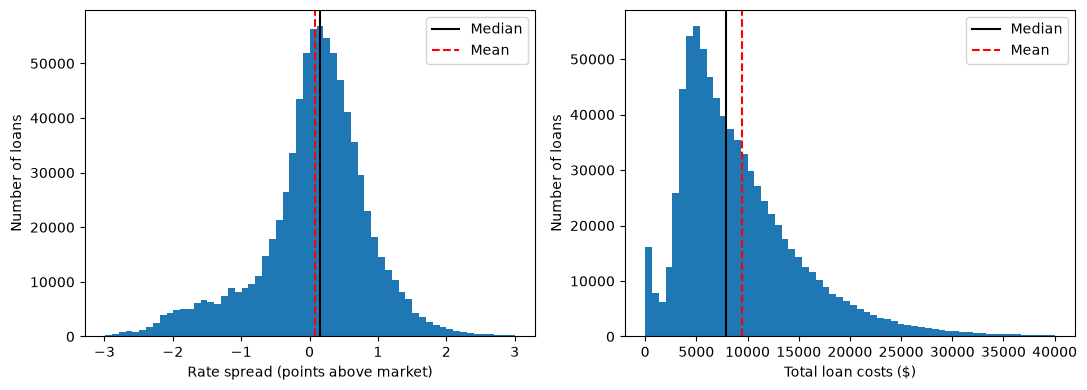

In [8]:
spread = clean["rate_spread"].dropna()
costs = clean["total_loan_costs"].dropna()

print("Rate spread:      mean =", round(spread.mean(), 2), "| median =", round(spread.median(), 2))
print("Total loan costs: mean =", round(costs.mean()), "| median =", round(costs.median()), "| max =", round(costs.max()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(spread[spread.between(-3, 3)], bins=60)
axes[0].axvline(spread.median(), color="black", label="Median")
axes[0].axvline(spread.mean(), color="red", linestyle="--", label="Mean")
axes[0].set_xlabel("Rate spread (points above market)")
axes[0].set_ylabel("Number of loans")
axes[0].legend()

axes[1].hist(costs[costs.between(0, 40000)], bins=60)
axes[1].axvline(costs.median(), color="black", label="Median")
axes[1].axvline(costs.mean(), color="red", linestyle="--", label="Mean")
axes[1].set_xlabel("Total loan costs ($)")
axes[1].set_ylabel("Number of loans")
axes[1].legend()

plt.tight_layout()
plt.show()

**Finding:** loan costs are right-skewed (mean above median, with a long tail of very expensive loans),
and rate spread has extreme values. So prices are summarized with **medians**, and extreme but valid
values are kept.

## Step 7 · Question 1: Does a smaller down payment mean a higher price?

We compare the **median rate spread** (APR above the market benchmark) across down-payment groups,
for conventional, FHA and VA loans. Groups with fewer than 100 loans are hidden.
**Spearman correlation** checks whether the spread rises as loan-to-value rises.

Median rate spread (points above market):


loan_type_label,Conventional,FHA,VA
down_payment_band,,,
20%+ down,0.03,0.24,-0.54
10-20% down,0.23,0.14,-0.53
5-10% down,0.39,0.21,-0.51
3-5% down,0.45,0.27,-0.51
Under 3% down,0.40,0.95,-0.46


Number of loans:


loan_type_label,Conventional,FHA,VA
down_payment_band,,,
20%+ down,262243,7207,8160
10-20% down,81604,13528,5831
5-10% down,94121,16041,4462
3-5% down,40726,148708,1195
Under 3% down,17442,37811,63658


Spearman correlation (loan-to-value vs rate spread):
   Conventional: 0.34
   FHA: 0.31
   VA: 0.06


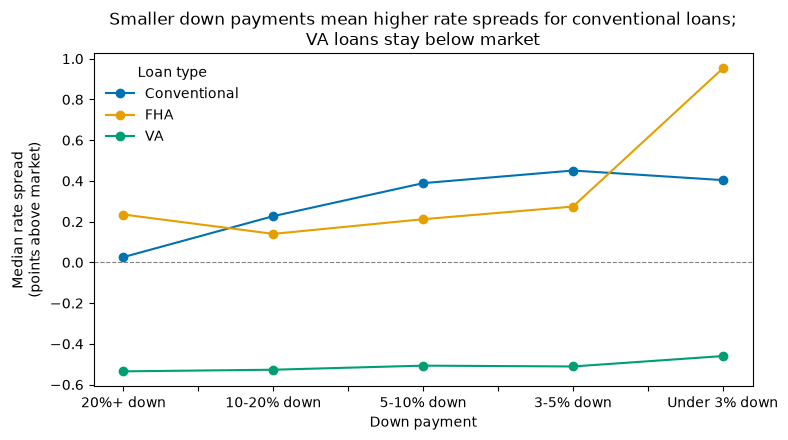

In [9]:
q1 = clean[clean["loan_type_label"].isin(["Conventional", "FHA", "VA"])]
q1 = q1.dropna(subset=["rate_spread"])

# Median rate spread and number of loans, for each loan type and down-payment group
medians = q1.pivot_table(index="down_payment_band", columns="loan_type_label",
                         values="rate_spread", aggfunc="median", observed=True)
counts = q1.pivot_table(index="down_payment_band", columns="loan_type_label",
                        values="rate_spread", aggfunc="count", observed=True)
print("Median rate spread (points above market):")
display(medians.round(2))
print("Number of loans:")
display(counts)

# Spearman correlation per loan type
print("Spearman correlation (loan-to-value vs rate spread):")
for loan_type in ["Conventional", "FHA", "VA"]:
    subset = q1[q1["loan_type_label"] == loan_type]
    corr = subset["loan_to_value_ratio"].corr(subset["rate_spread"], method="spearman")
    print(f"   {loan_type}: {corr:.2f}")

# Hide groups with fewer than 100 loans, then plot (color-blind-safe colors)
medians = medians.where(counts >= 100)
ax = medians.plot(marker="o", figsize=(8, 4.5), color=["#0072B2", "#E69F00", "#009E73"])
ax.axhline(0, color="grey", linestyle="--", linewidth=0.8)   # 0 = priced at the market rate
ax.set_xlabel("Down payment")
ax.set_ylabel("Median rate spread\n(points above market)")
ax.set_title("Smaller down payments mean higher rate spreads for conventional loans;\nVA loans stay below market")
ax.legend(title="Loan type", frameon=False)
plt.tight_layout()
plt.show()

**Interpretation:** for conventional loans, a smaller down payment means a higher price: the median
rate spread rises from 0.03 points (20%+ down) to 0.45 points (3–5% down), with a Spearman
correlation of 0.34. This fits private mortgage insurance, which is required below 20% down and
included in the APR. FHA stays flat until under 3% down, where it jumps to 0.95. VA loans stay below
the market rate (about −0.5) at every down payment.

**Limitation:** HMDA has no credit scores, so part of the higher price may come from lower credit
scores rather than the smaller down payment.

## Step 8 · Question 2: Do closing costs differ across states?

Total loan costs are compared by state, **in dollars** and **as a % of the loan**. States are ordered
expensive → mid → low. Boxes show the middle 50% of loans; the line is the median.
Costs above 20% of the loan are excluded as likely errors.

,loans,median_cost_dollars,median_cost_pct,median_loan_amount
state_code,,,,
CA,161724,10022.86,2.01,545000.0
MA,36961,5632.10,1.29,485000.0
FL,192835,8954.81,2.80,345000.0
TX,248039,8590.49,2.92,305000.0
MI,69162,4521.80,2.11,235000.0
OH,88256,5349.35,2.52,235000.0


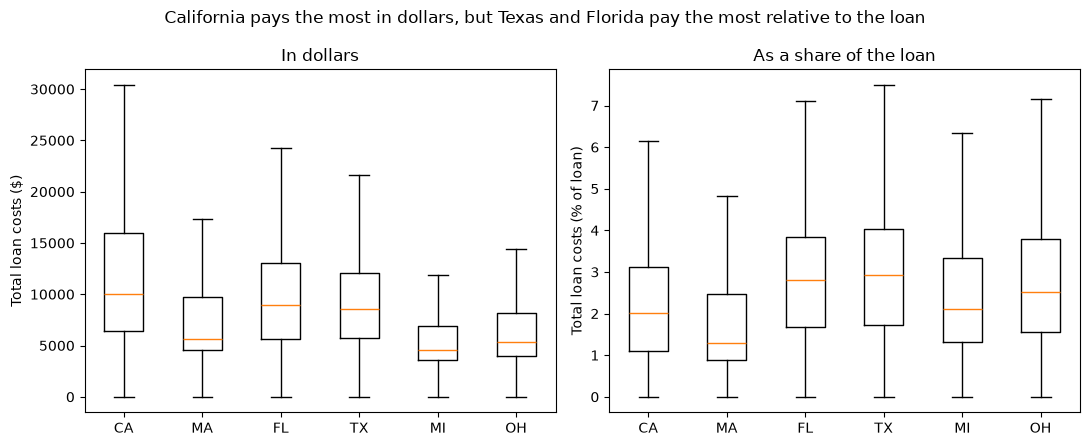

In [10]:
q2 = clean.dropna(subset=["total_loan_costs"])
q2 = q2[q2["loan_costs_pct"] <= 20]

summary = q2.groupby("state_code").agg(
    loans=("total_loan_costs", "count"),
    median_cost_dollars=("total_loan_costs", "median"),
    median_cost_pct=("loan_costs_pct", "median"),
    median_loan_amount=("loan_amount", "median"),
)
display(summary.loc[STATES].round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

dollars = [q2[q2["state_code"] == s]["total_loan_costs"] for s in STATES]
axes[0].boxplot(dollars, tick_labels=STATES, showfliers=False)
axes[0].set_title("In dollars")
axes[0].set_ylabel("Total loan costs ($)")

percent = [q2[q2["state_code"] == s]["loan_costs_pct"] for s in STATES]
axes[1].boxplot(percent, tick_labels=STATES, showfliers=False)
axes[1].set_title("As a share of the loan")
axes[1].set_ylabel("Total loan costs (% of loan)")

fig.suptitle("California pays the most in dollars, but Texas and Florida pay the most relative to the loan")
plt.tight_layout()
plt.show()

**Interpretation:** in dollars, California pays the most (\\$10,023) and Michigan the least (\\$4,522).
As a share of the loan, Texas (2.92%) and Florida (2.80%) pay the most, and Massachusetts the least
(1.29%). So closing costs don't simply follow home prices.

**Limitation:** total loan costs include many different fees, so differences between states may
partly come from the mix of loan types.

## Summary

| Stage | Loans |
|---|---|
| Downloaded (6 states, home purchase) | 2,282,462 |
| Comparable applications (notebook 01) | 1,747,609 |
| Approved loans | 970,201 |
| **Cleaned: 30-year fixed, valid values** | **810,670** |

**Decisions:** D7 approved loans only, no imputation · D9 30-year fixed-rate loans only ·
D10 impossible values removed, extreme values kept · D11 down-payment bands and costs as % of loan.

**Findings:** a smaller down payment means a higher price for conventional loans; closing costs are
highest in dollars in California but highest relative to the loan in Texas and Florida.

**Output:** `data/processed/hmda_2025_pricing_clean.parquet`, used by the Streamlit app.

In [12]:
from pathlib import Path
f = Path(r"C:\Users\havil\CMSE_midterm_HMDA_project\data\processed\hmda_2025_pricing_clean.parquet")
print(round(f.stat().st_size / 1e6, 1), "MB")

17.9 MB
